# Curve fitting, stochastic rates, deposit models, the 2024 recalibration and the open-source gap

**Question:** how much does it matter which published method a validator picks for the IRRBB of the bank that failed in 2023: how far do the curve family, the first-order approximations, the treatment of the deposits and the 2024 recalibration move its EVE and NII, where does the engine stop, and does any choice change the verdict?

- **Level:** 3, comparison with published methods
- **Prerequisites:** notebooks 01 to 06 of this topic
- **Reading time:** about 55 minutes

## Objectives

By the end of this notebook you can:

- place the methods of the case (Nelson-Siegel and Svensson curves, dynamic Nelson-Siegel, Hull-White scenarios, the replicating portfolio, the deposit beta, prepayment models) in the published literature the research found, with its sources, and say what the engine implements and what it does not;
- measure how much the choice of curve family moves the EVE of the same balance sheet;
- compare the first-order gap and duration approximations with the full revaluation and with the dynamic NII on the same three dates, and say when they disagree even in sign;
- compare three treatments of the deposits (every deposit overnight, the standard's caps, and the internal replicating portfolio) on the same flows;
- read the 2016 and the 2024 calibrations side by side, and state what is known about the open-source tools that could challenge the results.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==1.1.0 numpy==2.4.6 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from riskvalidation.irrbb import curves, eve_nii, shocks, slotting

for name in ("riskvalidation", "numpy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 1.0.1
numpy 2.4.6
matplotlib 3.11.2


## Data

The data is case C14, the interest rate risk in the banking book (IRRBB) of the bank that failed in March 2023, at three valuation dates, 2021-Q4, 2022-Q2 and 2022-Q4, as Contraste commits it: the FDIC call reports (FDIC BankFind financials, https://api.fdic.gov/banks/financials) and the US Treasury par curve (https://home.treasury.gov/resource-center/data-chart-center/interest-rates), public-domain sources of the licence class `mirror-allowed`. The bank is **real in aggregate and synthetic in behaviour**. Money is in USD thousands and a positive delta EVE is a loss.

- **Files read:** `data/derived/C14/vd-2021-q4.json`, `vd-2022-q2.json` and `vd-2022-q4.json` (`outputs.balance_sheet`, `curve`, `scenarios`, `behavioural_comparison`, `ladder`, `dynamic_nii`, `nmd_segments`) and `models-svb-2021-2022.json` (`fit.nmd_models`, the replicating fits). The research notes behind the published literature are the dossiers 01 (Basel framework), 03 (Chile) and 05 (market, ALM and liquidity models) of the Contraste research.

The level 3 notebook compares, on the same data, what the case does (levels 1 and 2) with what the literature offers. The next cell loads the files and rebuilds, for each date, the net flows of the balance sheet under the behavioural and the contractual treatment (as in notebook 01).

In [2]:
# Load the three dates and the model document; rebuild the net flows of each treatment and the zero rates
ROOT = Path("../../..").resolve()
derived = ROOT / "data" / "derived" / "C14"
quarters = ("2021-Q4", "2022-Q2", "2022-Q4")
docs = {q: json.loads((derived / f"vd-{q.lower()}.json").read_text(encoding="utf-8")) for q in quarters}
fit = json.loads((derived / "models-svb-2021-2022.json").read_text(encoding="utf-8"))["fit"]
MID = slotting.bucket_grid().midpoints
LANG = "en"  # the bilingual fields of the documents are read in this language
NAME = {"behavioural": "behavioural", "contractual": "contractual"}
NAME.update({"parallel-up": "parallel up", "parallel-down": "parallel down", "steepener": "steepener"})
NAME.update({"flattener": "flattener", "short-up": "short up", "short-down": "short down"})
book = {}
for q, d in docs.items():
    o = d["outputs"]
    sides = {}
    for treatment in ("behavioural", "contractual"):
        a, l = np.zeros(19), np.zeros(19)
        for item in o["balance_sheet"]["items"]:
            target, sign = (a, 1.0) if item["side"] == "asset" else (l, -1.0)
            for row in item["cash_flows"][treatment]:
                target[row["bucket"] - 1] += sign * row["amount"]
        sides[treatment] = (a, l)
    r0 = np.array(o["curve"]["zero_rates_at_midpoints"])
    book[q] = {"flows": sides, "r0": r0, "tier1": o["scenarios"][0]["outlier"]["tier1"]}
    print(q, o["valuation_date"], "| Tier 1", f"{book[q]['tier1']:,.0f}")

2021-Q4 2021-12-31 | Tier 1 14,622,000
2022-Q2 2022-06-30 | Tier 1 16,349,000
2022-Q4 2022-12-31 | Tier 1 16,995,000


## Method

Each comparison below uses the same committed flows and curves as the level 2 notebooks and changes one choice at a time, so a difference in the result is attributable to that choice. There are four comparisons: (1) the curve family, (2) the first-order approximations against the full revaluation and the dynamic projection, (3) three treatments of the deposits, and (4) the 2016 and 2024 calibrations. All four run the engine on the committed flows and curves. Each is introduced with the published literature it stands for, in the next section.

## Comparison

The research (dossier 05, D.1 to D.7, and dossier 01, H) found the following families for each part of the IRRBB measurement. The right-hand column says what the engine `riskvalidation` 1.0.1 implements and what it does not, from its source at the tag.

| Part | Published literature (source) | In the engine |
|---|---|---|
| Curve fitting | Nelson and Siegel (1987, https://doi.org/10.1086/296409); Svensson (1994, https://doi.org/10.3386/w4871); dynamic Nelson-Siegel, Diebold and Li (2006, https://doi.org/10.1016/j.jeconom.2005.03.005) | `fit_nelson_siegel`, `fit_svensson`, `fit_dns_factors`, `forecast_dns_factors`; the decay 0.0609 per month is a constant |
| Interpolation | Hagan and West (2006, https://doi.org/10.1080/13504860500396032): monotone convex and other schemes change forwards materially | linear in tenor, flat outside the grid (`zero_rates_at`); no other scheme |
| Short-rate scenarios | Vasicek (1977, https://doi.org/10.1016/0304-405X(77)90016-2); Hull and White (1990, https://doi.org/10.1093/rfs/3.4.573) | `hw1f_scenarios` (Hull-White one-factor, antithetic); no Vasicek |
| Non-maturity deposits | static replicating portfolio (BCBS d368, footnote 38); contingent-claim valuation, Jarrow and van Deventer (1998, https://doi.org/10.1016/S0378-4266(97)00058-7); three-factor model, Kalkbrener and Willing (2004, https://doi.org/10.1016/S0378-4266(03)00131-6); stochastic programming, Frauendorfer and Schurle (2003, https://doi.org/10.1016/S0377-2217(02)00626-4) | `replicating_portfolio` (static, exact up to 10 tranches); none of the other three |
| Deposit beta | asymmetric pass-through, Drechsler, Savov and Schnabl (2021, https://doi.org/10.1111/jofi.13013) | `deposit_beta_passthrough` (up and down betas); the fit is the pipeline's |
| Prepayment | SMM, CPR and PSA, Fuster, Lucca and Vickery (2022); rational exercise, Stanton (1995, https://doi.org/10.1093/rfs/8.3.677); proportional hazards, Schwartz and Torous (1989, https://doi.org/10.1111/j.1540-6261.1989.tb05062.x); competing risks, Deng, Quigley and Van Order (2000, https://doi.org/10.1111/1468-0262.00110) | `smm_from_cpr`, `cpr_from_smm`, `psa_cpr`, `prepayment_logit` and `fit_prepayment_logit` (a logit on incentive and seasoning; no burnout or seasonality) |
| Shock sizes | BCBS d368 (2016) and the recalibration d578 (2024, effective 2026-01-01): 99.9th percentile of six-month changes, 2000 to 2023, rounded to 25 bp | both tables as fixtures (`shock_table`); the 2016 table is verified with a text-layer caveat, the 2024 one is the SRP31.90 Table 2 |
| The lesson of the failed bank | the Federal Reserve's review found that the bank made counterintuitive assumptions about the duration of deposits to address a breach (https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf) | `eve_with_without_behavioural` and `behavioural_change_at_breach` (notebooks 05 and 08) |
| Open-source engines | the research found no mature open-source ALM or IRRBB engine; ORE and QuantLib cover curves, Hull-White and exposure, not a bank balance sheet (dossier 05, D.6 and I.3) | not applicable; the absence is a finding of the dossier's search, **UNVERIFIED** beyond it |

Two cautions on the table. The research notes that the 2024 values were not retrieved in the market dossier (dossier 05, D.2: "UNVERIFIED") and are transcribed in the Basel dossier (dossier 01, H.3); the engine takes the second. And the Diebold-Li decay is stated in the paper as maximising the curvature loading at 30 months; the engine documents 29.446 months (notebook 04).

### Comparison 1: the curve family

Hagan and West (2006) show that the interpolation scheme moves forward rates materially; the family fitted to the market curve does the same for the present values. The cell compares four ways of getting the 19 zero rates of each date from the same 12 observed yields: the pipeline's (bootstrap and linear interpolation), the Nelson-Siegel fit, the Svensson fit and the dynamic Nelson-Siegel loadings with the fixed decay. For each the cell recomputes the EVE of the behavioural net flows and prints the difference against the pipeline's, in money and as a share of Tier 1, and the largest gap in the rates.

curve | EVE | difference | share of Tier 1 | largest rate gap (bp)
2021-Q4 pipeline: bootstrap + linear          8,982,670          0   0.0000    0.0
2021-Q4 Nelson-Siegel                         8,813,494   -169,176  -0.0116   10.2
2021-Q4 Svensson                              8,961,548    -21,122  -0.0014   24.0
2021-Q4 dynamic Nelson-Siegel (fixed λ)       8,841,860   -140,810  -0.0096   11.7
2022-Q2 pipeline: bootstrap + linear          7,036,780          0   0.0000    0.0
2022-Q2 Nelson-Siegel                         7,142,430    105,650   0.0065   46.3
2022-Q2 Svensson                              6,647,794   -388,987  -0.0238   31.0
2022-Q2 dynamic Nelson-Siegel (fixed λ)       7,360,948    324,168   0.0198   37.4
2022-Q4 pipeline: bootstrap + linear          5,257,968          0   0.0000    0.0
2022-Q4 Nelson-Siegel                         5,284,342     26,374   0.0016   52.3
2022-Q4 Svensson                              4,996,362   -261,606  -0.0154   15.4
2022-Q4 dynamic Nels

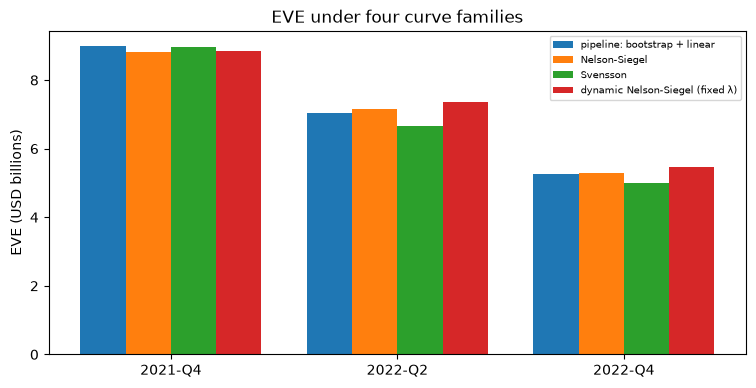

In [3]:
# EVE of the behavioural flows under four ways of getting the zero rates, against the pipeline's interpolated curve
families = {}
print("curve | EVE | difference | share of Tier 1 | largest rate gap (bp)")
for q, d in docs.items():
    pts = d["outputs"]["curve"]["points"]
    tenors = np.array([p["tenor_years"] for p in pts])
    zero = np.array([p["zero_rate"] for p in pts])
    ns = curves.fit_nelson_siegel(tenors, zero)
    sv = curves.fit_svensson(tenors, zero)
    factors = curves.fit_dns_factors(tenors * 12.0, zero[None, :])[0]
    rates = {"pipeline: bootstrap + linear": book[q]["r0"]}
    rates["Nelson-Siegel"] = curves.nelson_siegel_yield(MID, ns.beta0, ns.beta1, ns.beta2, ns.tau)
    rates["Svensson"] = curves.svensson_yield(MID, sv.beta0, sv.beta1, sv.beta2, sv.beta3, sv.tau1, sv.tau2)
    rates["dynamic Nelson-Siegel (fixed λ)"] = curves.dns_yield(MID * 12.0, *factors)
    a, l = book[q]["flows"]["behavioural"]
    for name, r in rates.items():
        families[(q, name)] = eve_nii.eve(a - l, r, MID)
        diff = families[(q, name)] - families[(q, "pipeline: bootstrap + linear")]
        gap = np.abs(r - book[q]["r0"]).max() * 1e4
        print(f"{q} {name:34s} {families[(q, name)]:12,.0f} {diff:10,.0f} {diff / book[q]['tier1']:8.4f} {gap:6.1f}")
fig, ax = plt.subplots(figsize=(9, 4.2))
names = list(dict.fromkeys(n for _, n in families))
for k, name in enumerate(names):
    ax.bar(np.arange(3) + k * 0.2 - 0.3, [families[(q, name)] / 1e6 for q in docs], 0.2, label=name)
ax.set_xticks(range(3), list(docs))
ax.set_ylabel("EVE (USD billions)")
ax.set_title("EVE under four curve families")
ax.legend(fontsize=7)
plt.show()

The four bars of each date are close but not equal. At 2022-Q2 the EVE runs from 6,647,794 under Svensson to 7,360,948 under the dynamic Nelson-Siegel loadings, around the 7,036,780 of the pipeline's curve: a spread of 713,154, which is 4.4 percent of Tier 1 and 10 percent of the EVE itself, and the largest gap in a single rate reaches 52.3 bp at 2022-Q4. The pipeline's curve passes through every observed point and the fitted families smooth them, with errors of 10 and 13 bp, so the comparison says how sensitive the result is to the choice of family, not which curve is right. The Basel measure is a ratio to Tier 1, so the choice does not change a verdict here, but it is a spread a validator should report. The figure shows one balance sheet and the behavioural flows only.

### Comparison 2: the first-order approximations, the full revaluation and the dynamic NII

Notebook 01 gave two first-order approximations, the repricing gap for the NII and the duration gap for the equity. They are cheap, they need no scenario curve, and the literature treats them as indicators; the standard asks for the full revaluation. The cell puts them side by side for a +200 bp parallel shock, the USD size of the 2024 table, on the three dates and the two treatments of the deposits. For the equity, the first-order change is $-DGAP \cdot A \cdot \Delta y$ (scaled from the +100 bp the engine returns, since it is linear in the shift), and the full revaluation is the engine's `delta_eve` of the +200 bp parallel shock on the same flows, loss-positive. For the NII, the gap approximation is twice the engine's value at +100 bp, and the dynamic projection is the committed one, loss-positive (a negative number is a gain).

deposits | equity: first order | equity: revaluation | NII: gap | NII: dynamic
2021-Q4 behavioural     5,549,598    4,696,651    455,806   -1,138,367
2021-Q4 contractual    17,508,990   15,540,829  2,471,558 -
2022-Q2 behavioural     4,016,983    3,389,057    398,114   -1,058,869
2022-Q2 contractual    14,096,514   12,611,087  2,398,976 -
2022-Q4 behavioural     3,602,676    3,056,308    349,294     -483,444
2022-Q4 contractual    12,246,721   10,981,705  2,186,939 -


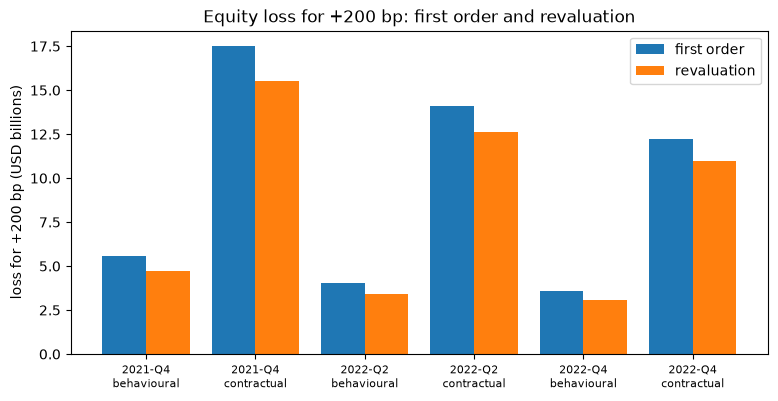

In [4]:
# Loss from the duration gap and from the full revaluation, and NII loss from the gap and from the dynamic projection
approx = {}
print("deposits | equity: first order | equity: revaluation | NII: gap | NII: dynamic")
for q, d in docs.items():
    o = d["outputs"]
    dynamic_up = next(s["delta_vs_base"] for s in o["dynamic_nii"]["scenarios"] if s["scenario"] == "parallel-up")
    shocked = shocks.apply_floor(book[q]["r0"], np.full(19, 200.0), 0.0)
    for treatment in ("behavioural", "contractual"):
        a, l = book[q]["flows"][treatment]
        dg = eve_nii.duration_gap(a, l, book[q]["r0"], MID)
        full = eve_nii.delta_eve(a - l, a - l, book[q]["r0"], shocked, MID)
        gap_nii = 2.0 * eve_nii.delta_nii_gap(eve_nii.repricing_gap(a, l), MID, 100.0)
        approx[(q, treatment)] = (-2.0 * dg.equity_change_100bp_up, full)
        dyn = f"{dynamic_up:12,.0f}" if treatment == "behavioural" else "-"
        print(f"{q} {NAME[treatment]:12s} {approx[(q, treatment)][0]:12,.0f} {full:12,.0f} {gap_nii:10,.0f} {dyn}")
fig, ax = plt.subplots(figsize=(9, 4.2))
keys = list(approx)
ax.bar(np.arange(len(keys)) - 0.2, [approx[k][0] / 1e6 for k in keys], 0.4, label="first order")
ax.bar(np.arange(len(keys)) + 0.2, [approx[k][1] / 1e6 for k in keys], 0.4, label="revaluation")
ax.set_xticks(range(len(keys)), [f"{q}\n{NAME[t]}" for q, t in keys], fontsize=8)
ax.set_ylabel("loss for +200 bp (USD billions)")
ax.set_title("Equity loss for +200 bp: first order and revaluation")
ax.legend()
plt.show()

The first-order loss overstates the revaluation by about 18 percent with the behavioural deposits at every date (5,549,598 against 4,696,651 at 2021-Q4, 4,016,983 against 3,389,057 at 2022-Q2, 3,602,676 against 3,056,308 at 2022-Q4) and by 11 to 13 percent with the contractual ones: the right order of magnitude and the right sign, with a bias that is stable across the dates, which is what the figure shows. The table printed above carries the NII, where the approximations do not agree even in sign: the repricing gap says that a +200 bp shock costs 455,806, 398,114 and 349,294, and the dynamic projection says that it earns 1,138,367, 1,058,869 and 483,444. The difference is the deposit pass-through: the gap reprices the non-core deposits one for one, the projection gives them a beta between 0.02 and 0.26. The sign of the NII sensitivity of this bank is a statement about its deposit beta.

### Comparison 3: three treatments of the deposits

The standard slots the stable part of the non-maturity deposits under caps; the internal practice replicates the deposit with a portfolio of rolling tranches and uses its average maturity. The cell takes the wholesale segment, the largest, and slots it three ways with the engine's `nmd_split`: every deposit overnight (the contractual reading), the standard's caps (the committed behavioural reading, 50 percent core at 4 years), and the **replicating** reading, where the whole balance sits at the average maturity of the committed replicating fit of the date (share 100 percent, no cap, `enforce_caps=False`). The rest of the balance sheet is kept as committed. For each treatment it prints the EVE and the loss under the +200 bp parallel shock with the zero floor, so the only thing that changes is the treatment of the wholesale deposits. This is a what-if on the committed flows (it omits the early redemption of term deposits, a 322,000 item, from the shocked flows), not a committed number.

In [5]:
# Slot the wholesale deposits three ways and compute the EVE and the loss under +200 bp with the zero floor
deposit = {}
print("treatment | average maturity (y) | EVE | loss for +200 bp | share of Tier 1")
for q, d in docs.items():
    o = d["outputs"]
    segment = next(s for s in o["nmd_segments"] if s["category"] == "wholesale")
    model = next(m for m in fit["nmd_models"] if m["valuation_date"] == o["valuation_date"])
    balance = segment["balance"]
    request = (segment["requested_core_share"], segment["requested_core_maturity_years"])
    standard = slotting.nmd_split(balance, "wholesale", *request)
    a, l = book[q]["flows"]["behavioural"]
    others = (a - l) + standard.flows
    wam_fit = model["weighted_average_maturity_years"]
    replicating = slotting.nmd_split(balance, "wholesale", 1.0, wam_fit, enforce_caps=False)
    treatments = {"contractual": slotting.nmd_split(balance, "wholesale", 0.0, 0.0), "standard caps": standard}
    treatments["replicating portfolio"] = replicating
    shocked = shocks.apply_floor(book[q]["r0"], np.full(19, 200.0), 0.0)
    for name, split in treatments.items():
        net = others - split.flows
        value = eve_nii.eve(net, book[q]["r0"], MID)
        loss = eve_nii.delta_eve(net, net, book[q]["r0"], shocked, MID)
        wam = float((split.flows * MID).sum() / split.flows.sum())
        deposit[(q, name)] = (value, loss)
        print(f"{q} {name:24s} {wam:8.4f} {value:14,.0f} {loss:14,.0f} {loss / book[q]['tier1']:8.4f}")

treatment | average maturity (y) | EVE | loss for +200 bp | share of Tier 1
2021-Q4 contractual                0.0028      4,868,904     11,542,342   0.7894
2021-Q4 standard caps              2.0014      8,982,670      4,696,651   0.3212
2021-Q4 replicating portfolio      4.7595     15,459,666     -4,423,382  -0.3025
2022-Q2 contractual                0.0028     -3,373,439      9,694,356   0.5930
2022-Q2 standard caps              2.0014      7,036,780      3,389,057   0.2073
2022-Q2 replicating portfolio      4.2049     18,465,257     -3,460,623  -0.2117
2022-Q4 contractual                0.0028     -7,338,446      8,571,364   0.5043
2022-Q4 standard caps              2.0014      5,257,968      3,056,308   0.1798
2022-Q4 replicating portfolio      5.0000     22,947,683     -4,607,251  -0.2711


The next cell draws the loss under +200 bp for the three treatments at the three dates.

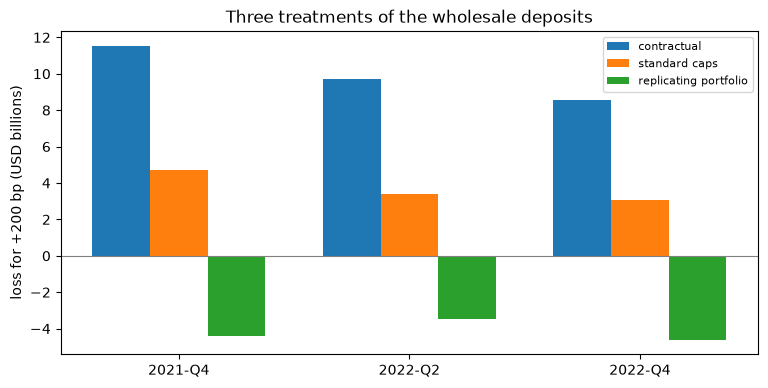

In [6]:
# Draw the loss under +200 bp for the three deposit treatments at the three dates
treat = list(dict.fromkeys(n for _, n in deposit))
fig, ax = plt.subplots(figsize=(9, 4.2))
for k, name in enumerate(treat):
    ax.bar(np.arange(3) + k * 0.25 - 0.25, [deposit[(q, name)][1] / 1e6 for q in docs], 0.25, label=name)
ax.axhline(0, color="grey", linewidth=0.8)
ax.set_xticks(range(3), list(docs))
ax.set_ylabel("loss for +200 bp (USD billions)")
ax.set_title("Three treatments of the wholesale deposits")
ax.legend(fontsize=8)
plt.show()

At 2022-Q2 the wholesale deposits, 185 billion of the balance, give three different banks. Slotted overnight, the EVE is -3,373,439 and the +200 bp loss 9,694,356, 59 percent of Tier 1. With the standard's caps, the EVE is 7,036,780 and the loss 3,389,057, 21 percent. With the replicating portfolio the whole balance sits at 4.2 years, the EVE is 18,465,257 and the +200 bp shock is a gain of 3,460,623, the bar below zero. The sign flips the same way at the three dates, with fitted maturities of 4.76, 4.20 and 5.00 years. This is the lever the review of the failed bank describes: a long deposit duration, fitted from the bank's own history, can make a loss disappear, and the caps of the standard are what stops it. Notebook 05 showed that the weights behind those maturities are not stable. The figure is a what-if on the committed flows, not a committed number.

### Comparison 4: the 2016 and the 2024 calibrations

The recalibration of the shock sizes (d578, effective 2026-01-01) is the one change of the standard in the period. The committed scenarios hold the six shocks under both tables with the capped behavioural flows, and the engine holds both size tables. The cell takes the USD sizes of each calibration, builds the six shocked curves of the behavioural flows with the zero floor, calls `eve_risk_measure` and the outlier test, and prints, for each date, the measure, the worst shock and the ratio to Tier 1; it draws the measure under both.

calibration | sizes (bp) | measure | worst shock | ratio
2021-Q4 2016 200/300/150    4,696,651 parallel up          0.3212
2021-Q4 2024 200/300/225    4,980,555 steepener            0.3406
2022-Q2 2016 200/300/150    3,389,057 parallel up          0.2073
2022-Q2 2024 200/300/225    3,418,160 steepener            0.2091
2022-Q4 2016 200/300/150    3,056,308 parallel up          0.1798
2022-Q4 2024 200/300/225    3,072,112 steepener            0.1808


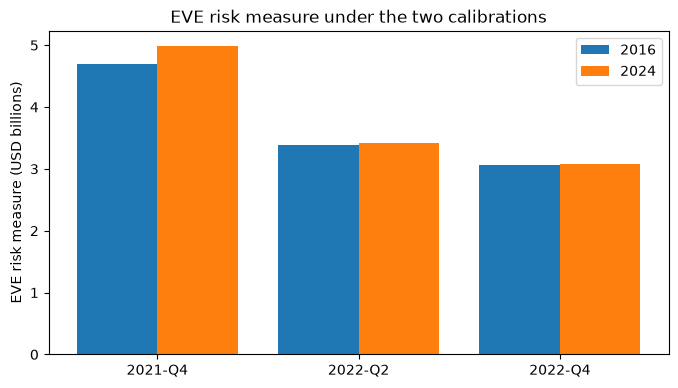

In [7]:
# The EVE risk measure under the 2016 and the 2024 calibrations, from the six shocked curves of the behavioural flows
cal_measure = {}
print("calibration | sizes (bp) | measure | worst shock | ratio")
for q in docs:
    a, l = book[q]["flows"]["behavioural"]
    net, r0 = a - l, book[q]["r0"]
    for cal in ("2016", "2024"):
        z = shocks.shock_size("USD", cal)
        deltas = []
        for s in shocks.SHOCKS:
            shape = shocks.shock_curve(s, z.parallel_bp, z.short_bp, z.long_bp, MID)
            deltas.append(eve_nii.delta_eve(net, net, r0, shocks.apply_floor(r0, shape, 0.0), MID))
        measure = eve_nii.eve_risk_measure(np.array(deltas).reshape(6, 1))
        worst = shocks.SHOCKS[int(np.argmax(deltas))]
        ratio = eve_nii.outlier_test(measure, book[q]["tier1"]).ratio
        cal_measure[(q, cal)] = measure
        sizes = f"{z.parallel_bp:.0f}/{z.short_bp:.0f}/{z.long_bp:.0f}"
        print(f"{q} {cal} {sizes} {measure:12,.0f} {NAME[worst]:20s} {ratio:.4f}")
fig, ax = plt.subplots(figsize=(8, 4.2))
for k, cal in enumerate(("2016", "2024")):
    ax.bar(np.arange(3) + k * 0.4 - 0.2, [cal_measure[(q, cal)] / 1e6 for q in docs], 0.4, label=cal)
ax.set_xticks(range(3), list(docs))
ax.set_ylabel("EVE risk measure (USD billions)")
ax.set_title("EVE risk measure under the two calibrations")
ax.legend()
plt.show()

Under the 2016 sizes the worst shock is the parallel-up one at the three dates; under the 2024 sizes, whose long size is 225 bp instead of 150 bp, it is the steepener. The measure rises by 6.0 percent at 2021-Q4 (4,696,651 to 4,980,555), 0.9 percent at 2022-Q2 and 0.5 percent at 2022-Q4, as the bars show, and the ratio under the 2024 sizes, 0.3406, 0.2091 and 0.1808, stays over the line of 0.15 at every date: the recalibration changes the shape that hurts most, not the verdict of this case. The figures are recomputed from the behavioural flows with the zero floor and differ from the pipeline's committed measure by a few hundred, the early redemption of term deposits left out. The picture is one currency's sizes on one bank.

## Results

**Answer:** no choice among the four changes the verdict that the bank is over the 15 percent line, but the deposit treatment changes the sign of the loss. At 2022-Q2 the +200 bp loss is 9,694,356 with every deposit overnight, 3,389,057 with the standard's caps and a gain of 3,460,623 with the replicating portfolio; the curve family moves the EVE between 6,647,794 and 7,360,948 around the 7,036,780 of the pipeline; the gap and the dynamic projection disagree in sign on the NII (a cost of 398,114 against a gain of 1,058,869); and the 2024 recalibration raises the measure by 6.0 percent at 2021-Q4 and makes the steepener the worst shock, at a ratio of 0.2091 at 2022-Q2.

- **What the engine covers.** Of the families the research found, the engine implements the curve fits, Hull-White one factor, the static replicating portfolio, the deposit beta and a prepayment logit, and does not implement Vasicek, another interpolation scheme, the contingent-claim or three-factor deposit models, or stochastic programming. A validator who needs those has to bring a challenger from outside; the research found no mature open-source ALM engine to bring, a finding that stays unverified beyond the dossier's search.
- **The curve family.** On the same 12 observed yields the four ways of getting the 19 zero rates move the EVE by between -388,987 and +324,168 at 2022-Q2, at most 2.4 percent of Tier 1 but up to 10 percent of the EVE itself, with a largest gap of 52.3 bp in a single rate.
- **The first-order approximations.** For +200 bp the duration gap overstates the loss of the full revaluation by about 18 percent with the behavioural deposits and by 11 to 13 percent with the contractual ones: the right order of magnitude and sign, with a stable bias. The NII approximations do not agree even in sign: the gap says that +200 bp costs 455,806, 398,114 and 349,294, and the dynamic projection says that it earns 1,138,367, 1,058,869 and 483,444, because of the deposit pass-through.
- **The deposits.** At 2022-Q2 the EVE is -3,373,439 overnight, 7,036,780 with the caps and 18,465,257 with the replicating portfolio. The sign of the +200 bp loss flips at the three dates (average maturities of 4.76, 4.20 and 5.00 years). This is the lever the review of the failed bank describes; the caps of the standard stop it, and notebook 05 showed that the weights behind those maturities are not stable.
- **The 2024 recalibration.** Under the 2016 sizes the worst shock is the parallel-up at the three dates; under the 2024 sizes, whose long size is 225 bp instead of 150 bp, it is the steepener. The measure rises from 4,696,651 to 4,980,555 at 2021-Q4, and the ratio stays over 0.15 in every case.
- **What the notebook does not show.** That any of the alternatives is better than the pipeline's choices: there is no truth to compare against for a bank whose behaviour is synthetic. The notebook shows the size of the choices, so a validator knows where to look first: the deposit treatment, then the beta, then the curve.

## Summary

- The engine implements a part of the published literature: the curve families, Hull-White one factor, the static replicating portfolio, the deposit beta and a prepayment logit; it does not implement Vasicek, other interpolation schemes, the contingent-claim or the three-factor deposit models, or stochastic programming.
- The curve family moves the EVE of the same flows by a small share of Tier 1; the deposit treatment moves the loss by a multiple.
- The first-order approximations give the order of magnitude of the equity change but the gap and the dynamic NII can differ even in sign, because they treat the deposit pass-through differently.
- The 2024 recalibration changes the sizes of the long end and so the worst shock of the case, from the parallel-up to the steepener, without changing the verdict of the outlier test.
- No mature open-source engine was found to challenge the results; that is a finding of the dossier's search, unverified beyond it.

**What to try next.** Replace the +200 bp of comparison 3 by the steepener of notebook 02 and see whether the order of the three deposit treatments holds. Then continue with notebook 08, the components beyond the published literature.

## References

- Nelson, C. R. and Siegel, A. F. (1987), Parsimonious modeling of yield curves, Journal of Business 60(4). https://doi.org/10.1086/296409
- Svensson, L. E. O. (1994), Estimating and interpreting forward interest rates: Sweden 1992-1994, NBER Working Paper 4871. https://doi.org/10.3386/w4871
- Diebold, F. X. and Li, C. (2006), Forecasting the term structure of government bond yields, Journal of Econometrics 130(2). https://doi.org/10.1016/j.jeconom.2005.03.005
- Hagan, P. S. and West, G. (2006), Interpolation methods for curve construction, Applied Mathematical Finance 13(2). https://doi.org/10.1080/13504860500396032
- Vasicek, O. (1977), An equilibrium characterization of the term structure, Journal of Financial Economics 5(2). https://doi.org/10.1016/0304-405X(77)90016-2
- Hull, J. and White, A. (1990), Pricing interest-rate-derivative securities, Review of Financial Studies 3(4). https://doi.org/10.1093/rfs/3.4.573
- Jarrow, R. and van Deventer, D. (1998), The arbitrage-free valuation and hedging of demand deposits and credit card loans, Journal of Banking and Finance 22(3). https://doi.org/10.1016/S0378-4266(97)00058-7
- Kalkbrener, M. and Willing, J. (2004), Risk management of non-maturing liabilities, Journal of Banking and Finance 28(7). https://doi.org/10.1016/S0378-4266(03)00131-6
- Frauendorfer, K. and Schurle, M. (2003), Multistage stochastic programming: optimal reinvestment of non-maturing liabilities, European Journal of Operational Research 151(3). https://doi.org/10.1016/S0377-2217(02)00626-4
- Drechsler, I., Savov, A. and Schnabl, P. (2021), Banking on deposits: maturity transformation without interest rate risk, Journal of Finance 76(3). https://doi.org/10.1111/jofi.13013
- Stanton, R. (1995), Rational prepayment and the valuation of mortgage-backed securities, Review of Financial Studies 8(3). https://doi.org/10.1093/rfs/8.3.677
- Schwartz, E. S. and Torous, W. N. (1989), Prepayment and the valuation of mortgage-backed securities, Journal of Finance 44(2). https://doi.org/10.1111/j.1540-6261.1989.tb05062.x
- Deng, Y., Quigley, J. M. and Van Order, R. (2000), Mortgage terminations, heterogeneity and the exercise of mortgage options, Econometrica 68(2). https://doi.org/10.1111/1468-0262.00110
- Fuster, A., Lucca, D. and Vickery, J. (2022), Mortgage-backed securities, FRBNY Staff Report 1001. https://www.newyorkfed.org/medialibrary/media/research/staff_reports/sr1001.pdf
- BCBS, Standards: Interest rate risk in the banking book, SRP31. https://www.bis.org/basel_framework/chapter/SRP/31.htm
- BCBS (2016), d368, Standards: Interest rate risk in the banking book. https://www.bis.org/bcbs/publ/d368.htm
- BCBS (2024), d578, Recalibration of shocks for interest rate risk in the banking book. https://www.bis.org/publications/202407-standards-recalibration-shocks-interest-rate-risk-banking-book.pdf
- Board of Governors of the Federal Reserve System (2023), Review of the Federal Reserve's Supervision and Regulation of Silicon Valley Bank. https://www.federalreserve.gov/publications/files/svb-review-20230428.pdf
- Dossiers 01, 03 and 05 of the Contraste research (Basel framework; Chile; market, ALM and liquidity models).